# 03_multirocket_hydra_comparison.ipynb — MultiRocket + Hydra - reproducing the paper's combination claim

**Author:** Aarti Bhosale

**Notebook:** `03_quant_hydra/notebooks/03_multirocket_hydra_comparison.ipynb`.

**Claim under test.** The Hydra paper (Dempster et al., 2023) states that Hydra *"can be combined with ROCKET and its variants to further improve the accuracy of these methods"*. The authors publish 30-resample results for the combinations (`hydra-authors-repo/results/results_ucr112_variants.csv`): over 112 UCR datasets, **Hydra+MultiRocket** has the highest mean accuracy of all variants (88.4 %, +1.0 pp over Hydra). The published file does **not** contain MultiRocket or MiniRocket on their own, so whether adding Hydra improves *MultiRocket* is not directly shown there. This notebook tests both questions on identical splits.

## Why resampled, harder datasets and reference scaling
On easy UCR datasets (e.g. Coffee, GunPoint, Wafer) every model reaches about 100 % accuracy, so differences come down to a few test cases, and one default split cannot separate models. This notebook therefore uses the same 18 datasets and resampling protocol as `04_quant_hydra_combinations.ipynb`. The ridge penalty is sensitive to feature scale, so every model's features are scaled as in the reference pipelines (aeon's `MiniRocketClassifier` / `MultiRocketClassifier`, which replace the original `RidgeClassifierCV(normalize=True)` removed in scikit-learn 1.2), and compared models receive identically scaled features.

## Models (all on the same split, the same Hydra kernels and the same MiniRocket/MultiRocket kernels)
| Name | Features | Scaling | Classifier |
|---|---|---|---|
| `MiniRocket` | MiniRocket, 10,000 kernels (aeon; 9,996 features) | `StandardScaler` | RidgeClassifierCV |
| `MultiRocket` | MultiRocket, 6,250 kernels (aeon; 49,728 features) | `StandardScaler` | RidgeClassifierCV |
| `Hydra` | Hydra, k = 8, g = 64 (official `hydra.py`) | official `SparseScaler` | RidgeClassifierCV |
| `Hydra+MiniRocket` | Hydra ‖ MiniRocket | each block scaled as above | RidgeClassifierCV |
| `Hydra+MultiRocket` | Hydra ‖ MultiRocket | each block scaled as above | RidgeClassifierCV |

This is the same construction as aeon's `MultiRocketHydraClassifier` (SparseScaler on Hydra, StandardScaler on MultiRocket, concatenate, ridge). Scalers are fitted on training data only. Because `RidgeClassifierCV` fits an intercept, centring the features has no effect on the solution, so one standardised copy of each block is shared by the single and combined models.

## Protocol
* **Datasets:** the 18 datasets of `04_quant_hydra_combinations.ipynb` (6 Hydra-favoured, 6 QUANT-favoured, 6 neutral, chosen from published results before any run). The group labels come from that experiment; here they are only used for breakdowns.
* **Accuracy:** 10 resamples per dataset; resample 0 = default split, resample *i* = `aeon` `stratified_resample_data(random_state=i)` - the same splits as the other notebooks. Hydra seed, MiniRocket seed and MultiRocket seed = resample id. Ridge alphas `np.logspace(-3, 3, 10)` (authors' README). The published means use 30 resamples; the comparison with them accounts for n = 10 vs 30.
* **Cost:** isolated single-thread timing runs, one task at a time, on resample 0 of every dataset (timings from parallel runs are inflated by contention between worker processes).

## Outputs (`03_quant_hydra/results/multirocket_hydra/`)
* `runs/` - one CSV per (dataset, resample) accuracy task (resumable)
* `timing/` - one CSV per dataset from the isolated timing runs
* `mrh_runs.csv`, `mrh_timing.csv`, `mrh_vs_paper.csv`, `mrh_paired_tests.csv`, `mrh_summary.csv`, `plots/`

### Cell 1 - Imports

In [1]:
from pathlib import Path
from time import perf_counter
import importlib.util
import json
import os
import platform
import shutil
import sys
import traceback

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import stats
from threadpoolctl import threadpool_limits
from joblib import Parallel, delayed

import aeon
import sklearn
from aeon.datasets import load_classification
from aeon.benchmarking.resampling import stratified_resample_data
from aeon.transformations.collection.convolution_based import MiniRocket, MultiRocket
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

### Cell 2 - Configuration and paths

In [2]:
HYDRA_FAVOURED = ["PigAirwayPressure", "PigCVP", "OSULeaf", "Rock", "ToeSegmentation1", "Wine"]
QUANT_FAVOURED = ["SemgHandMovementCh2", "EthanolLevel", "SemgHandSubjectCh2", "InlineSkate", "ScreenType", "Lightning2"]
NEUTRAL        = ["Herring", "Adiac", "Worms", "DistalPhalanxTW", "InsectWingbeatSound", "WormsTwoClass"]
DATASETS = HYDRA_FAVOURED + QUANT_FAVOURED + NEUTRAL
GROUP_OF = {**{d: "Hydra-favoured" for d in HYDRA_FAVOURED},
            **{d: "QUANT-favoured" for d in QUANT_FAVOURED},
            **{d: "Neutral" for d in NEUTRAL}}
GROUP_ORDER = ["Hydra-favoured", "QUANT-favoured", "Neutral"]

N_RESAMPLES = 10
N_PAPER_RESAMPLES = 30
N_WORKERS = 6
TIMING_RESAMPLE = 0
K, G = 8, 64
BATCH_SIZE = 256
ALPHAS = np.logspace(-3, 3, 10)

CONFIG_BLOCKS = {
    "MiniRocket": ("MiniR",),
    "MultiRocket": ("MR",),
    "Hydra": ("H",),
    "Hydra+MiniRocket": ("H", "MiniR"),
    "Hydra+MultiRocket": ("H", "MR"),
}
CONFIGS = list(CONFIG_BLOCKS)

from pathlib import Path
import sys

# Repository root = the folder that contains hydra-authors-repo/ (works from any working directory)
ROOT = Path.cwd().resolve()
while not (ROOT / "hydra-authors-repo").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the hydra-time-series-project repository.")
    ROOT = ROOT.parent

HYDRA_CODE  = ROOT / "hydra-authors-repo" / "code"        # official hydra.py
AUTHORS_RES = ROOT / "hydra-authors-repo" / "results"     # published Hydra results
DATA_DIR    = ROOT / "data" / "ucr_tsml"                  # local UCR cache (git-ignored)
FOLDER      = ROOT / "03_quant_hydra"
REF_DIR     = FOLDER / "reference_results"                # QUANT published accuracies
RESULTS_DIR = FOLDER / "results" / "multirocket_hydra"
PLOT_DIR    = RESULTS_DIR / "plots"
for d in (DATA_DIR, RESULTS_DIR, PLOT_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HYDRA_CODE))

# Names used in the rest of this notebook
PROJECT_ROOT = ROOT
HYDRA_SOURCE = HYDRA_CODE / "hydra.py"
PAPER_HYDRA = AUTHORS_RES / "results_ucr112_hydra.csv"
PAPER_VARIANTS = AUTHORS_RES / "results_ucr112_variants.csv"
OUT_DIR = RESULTS_DIR
TASK_DIR, TIMING_DIR = OUT_DIR / "runs", OUT_DIR / "timing"
for d in (DATA_DIR, TASK_DIR, TIMING_DIR, PLOT_DIR):
    d.mkdir(parents=True, exist_ok=True)

environment = {
    "python": sys.version.split()[0], "platform": platform.platform(), "processor": platform.processor(),
    "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
    "pytorch": torch.__version__, "aeon": aeon.__version__,
    "threads_per_task": 1, "parallel_workers": N_WORKERS, "cpu_count": os.cpu_count(),
}
(OUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2))
print(f"{len(DATASETS)} datasets x {N_RESAMPLES} resamples = {len(DATASETS) * N_RESAMPLES} accuracy tasks")
for key, value in environment.items():
    print(f"{key:17}: {value}")

18 datasets x 10 resamples = 180 accuracy tasks
python           : 3.11.0
platform         : Windows-10-10.0.26200-SP0
processor        : Intel64 Family 6 Model 170 Stepping 4, GenuineIntel
numpy            : 2.3.5
pandas           : 3.0.6
scikit_learn     : 1.9.1
pytorch          : 2.15.0+cpu
aeon             : 1.6.0
threads_per_task : 1
parallel_workers : 6
cpu_count        : 18


### Cell 3 - Published results for the datasets used

`paper_*` are the authors' 30-resample means. MultiRocket and MiniRocket alone are not in the published file.

In [3]:
paper = (pd.read_csv(PAPER_HYDRA)[["dataset", "accuracy"]].rename(columns={"accuracy": "paper_Hydra"})
         .merge(pd.read_csv(PAPER_VARIANTS)[["dataset", "Hydra+MiniRocket", "Hydra+MultiRocket"]]
                .rename(columns={"Hydra+MiniRocket": "paper_Hydra+MiniRocket", "Hydra+MultiRocket": "paper_Hydra+MultiRocket"}),
                on="dataset"))
all112 = paper.copy()
gain112 = (all112["paper_Hydra+MultiRocket"] - all112["paper_Hydra"]) * 100
print(f"All 112 published datasets: Hydra+MultiRocket - Hydra = {gain112.mean():+.2f} pp "
      f"(better / same / worse: {(gain112 > 0).sum()} / {(gain112 == 0).sum()} / {(gain112 < 0).sum()})")
paper = paper.set_index("dataset").loc[DATASETS]
paper["paper gain H+MR over Hydra (pp)"] = (paper["paper_Hydra+MultiRocket"] - paper["paper_Hydra"]) * 100
paper.insert(0, "group", [GROUP_OF[d] for d in DATASETS])
print(f"Our 18 datasets: published Hydra+MultiRocket - Hydra = {paper['paper gain H+MR over Hydra (pp)'].mean():+.2f} pp")
display(paper.round(4))

All 112 published datasets: Hydra+MultiRocket - Hydra = +1.04 pp (better / same / worse: 65 / 6 / 41)
Our 18 datasets: published Hydra+MultiRocket - Hydra = +2.20 pp


,group,paper_Hydra,paper_Hydra+MiniRocket,paper_Hydra+MultiRocket,paper gain H+MR over Hydra (pp)
dataset,,,,,
PigAirwayPressure,Hydra-favoured,0.7404,0.8357,0.7234,-1.6988
PigCVP,Hydra-favoured,0.9111,0.9170,0.8535,-5.7532
OSULeaf,Hydra-favoured,0.9788,0.9730,0.9690,-0.9780
Rock,Hydra-favoured,0.8920,0.8733,0.8640,-2.8000
ToeSegmentation1,Hydra-favoured,0.9430,0.9436,0.9294,-1.3596
Wine,Hydra-favoured,0.9512,0.9438,0.9302,-2.0988
SemgHandMovementCh2,QUANT-favoured,0.4927,0.5885,0.7717,27.8963
EthanolLevel,QUANT-favoured,0.6643,0.6833,0.7240,5.9667
SemgHandSubjectCh2,QUANT-favoured,0.7806,0.8458,0.9173,13.6740


### Cell 4 - Official Hydra, data loading and resampling

Same loading and resampling code as the other notebooks, so resample *i* is the same split everywhere.

In [4]:
def load_official_hydra():
    name = "hydra_official_impl"
    if name not in sys.modules:
        spec = importlib.util.spec_from_file_location(name, HYDRA_SOURCE)
        module = importlib.util.module_from_spec(spec)
        sys.modules[name] = module
        spec.loader.exec_module(module)
    return sys.modules[name].Hydra, sys.modules[name].SparseScaler


Hydra, SparseScaler = load_official_hydra()
import cloudpickle   # hydra.py is loaded from a file path: send it to worker processes by value
cloudpickle.register_pickle_by_value(sys.modules["hydra_official_impl"])

_default_splits = {}

def load_default_split(name):
    if name not in _default_splits:
        def _load():
            Xtr, ytr = load_classification(name, split="train", extract_path=str(DATA_DIR), return_metadata=False)
            Xte, yte = load_classification(name, split="test", extract_path=str(DATA_DIR), return_metadata=False)
            return Xtr, ytr, Xte, yte
        try:
            Xtr, ytr, Xte, yte = _load()
        except OSError as exc:   # truncated download -> delete cached copy, retry once
            print(f"{name}: could not parse cached files ({exc}); re-downloading.")
            shutil.rmtree(DATA_DIR / name, ignore_errors=True)
            Xtr, ytr, Xte, yte = _load()
        _default_splits[name] = (np.asarray(Xtr, dtype=np.float32), np.asarray(ytr).astype(str),
                                 np.asarray(Xte, dtype=np.float32), np.asarray(yte).astype(str))
    return _default_splits[name]


def get_resample(name, resample_id):
    Xtr, ytr, Xte, yte = load_default_split(name)
    if resample_id == 0:
        return Xtr, ytr, Xte, yte
    Xtr, ytr, Xte, yte = stratified_resample_data(Xtr, ytr, Xte, yte, random_state=resample_id)
    return (np.asarray(Xtr, dtype=np.float32), np.asarray(ytr).astype(str),
            np.asarray(Xte, dtype=np.float32), np.asarray(yte).astype(str))


manifest = []
for name in DATASETS:   # download once, serially, before any parallel work
    Xtr, ytr, Xte, yte = load_default_split(name)
    manifest.append({"dataset": name, "group": GROUP_OF[name], "n_train": len(ytr), "n_test": len(yte),
                     "series_length": Xtr.shape[-1], "n_classes": len(np.unique(ytr))})
manifest = pd.DataFrame(manifest)
display(manifest)

,dataset,group,n_train,n_test,series_length,n_classes
0,PigAirwayPressure,Hydra-favoured,104,208,2000,52
1,PigCVP,Hydra-favoured,104,208,2000,52
2,OSULeaf,Hydra-favoured,200,242,427,6
3,Rock,Hydra-favoured,20,50,2844,4
4,ToeSegmentation1,Hydra-favoured,40,228,277,2
5,Wine,Hydra-favoured,57,54,234,2
6,SemgHandMovementCh2,QUANT-favoured,450,450,1500,6
7,EthanolLevel,QUANT-favoured,504,500,1751,4
8,SemgHandSubjectCh2,QUANT-favoured,450,450,1500,5
9,InlineSkate,QUANT-favoured,100,550,1882,7


### Cell 5 - One task: three transforms, five models

The three feature blocks are computed once and shared. Per model: training time = transform + scaling time of its blocks + ridge fit; test time = test transform + scaling + prediction.

In [5]:
def run_task(name, resample):
    torch.set_num_threads(1)
    with threadpool_limits(limits=1):
        Xtr, ytr, Xte, yte = get_resample(name, resample)
        F, t_tr, t_te = {}, {}, {}

        def rocket_block(key, transformer):
            t = perf_counter()
            transformer.fit(Xtr)
            scaler = StandardScaler()
            Ztr = scaler.fit_transform(transformer.transform(Xtr)).astype(np.float32)
            t_tr[key] = perf_counter() - t
            t = perf_counter()
            Zte = scaler.transform(transformer.transform(Xte)).astype(np.float32)
            t_te[key] = perf_counter() - t
            F[key] = (Ztr, Zte)

        rocket_block("MiniR", MiniRocket(n_kernels=10000, max_dilations_per_kernel=32, n_jobs=1, random_state=resample))
        rocket_block("MR", MultiRocket(n_kernels=6250, max_dilations_per_kernel=32, n_features_per_kernel=4,
                                       normalise=False, n_jobs=1, random_state=resample))

        t = perf_counter()
        hydra = Hydra(Xtr.shape[-1], k=K, g=G, seed=resample)
        h_scaler = SparseScaler()
        with torch.inference_mode():
            Htr = h_scaler.fit_transform(hydra.batch(torch.as_tensor(np.ascontiguousarray(Xtr)), batch_size=BATCH_SIZE)).numpy()
        t_tr["H"] = perf_counter() - t
        t = perf_counter()
        with torch.inference_mode():
            Hte = h_scaler.transform(hydra.batch(torch.as_tensor(np.ascontiguousarray(Xte)), batch_size=BATCH_SIZE)).numpy()
        t_te["H"] = perf_counter() - t
        F["H"] = (Htr, Hte)

        rows = []
        for config, blocks in CONFIG_BLOCKS.items():
            Ztr = np.concatenate([F[b][0] for b in blocks], 1) if len(blocks) > 1 else F[blocks[0]][0]
            Zte = np.concatenate([F[b][1] for b in blocks], 1) if len(blocks) > 1 else F[blocks[0]][1]
            t = perf_counter()
            clf = RidgeClassifierCV(alphas=ALPHAS).fit(Ztr, ytr)
            fit_s = perf_counter() - t
            t = perf_counter()
            pred = clf.predict(Zte)
            pred_s = perf_counter() - t
            rows.append({
                "dataset": name, "group": GROUP_OF.get(name, "-"), "resample": resample, "config": config,
                "n_train": len(ytr), "n_test": len(yte), "series_length": Xtr.shape[-1],
                "n_features": Ztr.shape[1],
                "accuracy": accuracy_score(yte, pred),
                "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
                "ridge_alpha": clf.alpha_,
                "alpha_at_upper": bool(np.isclose(clf.alpha_, ALPHAS.max())),
                "train_seconds": sum(t_tr[b] for b in blocks) + fit_s,
                "test_seconds": sum(t_te[b] for b in blocks) + pred_s,
            })
            del Ztr, Zte
    return rows

### Cell 6 - Smoke test (Wine, resample 1)

In [6]:
start = perf_counter()
smoke = pd.DataFrame(run_task("Wine", 1))
print(f"Wine r1 took {perf_counter() - start:.1f}s (first call includes numba compilation)")
display(smoke[["config", "n_features", "accuracy", "ridge_alpha", "train_seconds", "test_seconds"]].round(4))

Wine r1 took 1.7s (first call includes numba compilation)


,config,n_features,accuracy,ridge_alpha,train_seconds,test_seconds
0,MiniRocket,9996,0.9444,0.001,0.4077,0.0213
1,MultiRocket,49728,0.9630,0.001,0.4202,0.2249
2,Hydra,5120,0.9630,0.001,0.2808,0.2147
3,Hydra+MiniRocket,15116,0.9444,0.001,0.6834,0.2358
4,Hydra+MultiRocket,54848,0.9630,0.001,0.6990,0.4395


### Cell 7 - Accuracy: run all datasets × resamples (parallel, resumable)

Each finished task is written to `runs/<dataset>__rNN.csv`; complete files are skipped on re-run. Timings from these parallel runs are dropped (see Cell 7b).

In [7]:
def _task_file(d, r): return TASK_DIR / f"{d}__r{r:02d}.csv"

def _is_complete(d, r):
    try:
        return len(pd.read_csv(_task_file(d, r))) == len(CONFIGS)
    except Exception:
        return False

def _run_and_save(d, r):
    try:
        rows = run_task(d, r)
    except Exception:
        return d, r, traceback.format_exc()
    pd.DataFrame(rows).to_csv(_task_file(d, r), index=False)
    return d, r, None

todo = [(d, r) for d in DATASETS for r in range(N_RESAMPLES) if not _is_complete(d, r)]
print(f"{len(todo)} of {len(DATASETS) * N_RESAMPLES} tasks to run")
if todo:
    wall = perf_counter()
    jobs = Parallel(n_jobs=N_WORKERS, return_as="generator_unordered")(delayed(_run_and_save)(d, r) for d, r in todo)
    for i, (d, r, err) in enumerate(jobs, 1):
        if err:
            print(f"FAILED {d} r{r}\n{err}")
        if i % 30 == 0 or i == len(todo):
            print(f"[{i:3d}/{len(todo)}] {(perf_counter() - wall) / 60:.1f} min elapsed")

runs = pd.concat([pd.read_csv(_task_file(d, r)) for d in DATASETS for r in range(N_RESAMPLES)], ignore_index=True)
runs = runs.drop(columns=["train_seconds", "test_seconds"])   # contended timings: not used
runs.to_csv(OUT_DIR / "mrh_runs.csv", index=False)
print("Rows:", len(runs), "| resamples per dataset:", runs.groupby("dataset")["resample"].nunique().min())

0 of 180 tasks to run


Rows: 900 | resamples per dataset: 10


### Cell 7b - Cost: isolated single-thread timing runs

Resample 0 of every dataset, one task at a time (no parallel workers).

In [8]:
wall = perf_counter()
for d in DATASETS:
    f = TIMING_DIR / f"{d}.csv"
    if f.exists():
        continue
    pd.DataFrame(run_task(d, TIMING_RESAMPLE)).to_csv(f, index=False)
    print(f"{d:22s} timed ({(perf_counter() - wall) / 60:.1f} min elapsed)")
timing = pd.concat([pd.read_csv(TIMING_DIR / f"{d}.csv") for d in DATASETS], ignore_index=True)
timing.to_csv(OUT_DIR / "mrh_timing.csv", index=False)
print("Timing rows:", len(timing))

Timing rows: 90


### Cell 8 - Reproduction check against the published means

For Hydra, Hydra+MiniRocket and Hydra+MultiRocket: `z = diff / (sd·√(1/10 + 1/30))`, `sd` = our spread across resamples floored at `1/n_test`; |z| ≤ 1.96 = within expected variance. We also check whether our **gain from adding MultiRocket to Hydra** follows the published gain per dataset.

In [ ]:
acc = runs.pivot_table(index=["dataset", "resample"], columns="config", values="accuracy")[CONFIGS]
mean_acc = acc.groupby("dataset").mean().loc[DATASETS]
sd_acc = acc.groupby("dataset").std().loc[DATASETS]
n_test = runs.groupby("dataset")["n_test"].first().loc[DATASETS]
n_res = acc.groupby("dataset").size().loc[DATASETS]

checks = []
for model in ("Hydra", "Hydra+MiniRocket", "Hydra+MultiRocket"):
    p = paper[f"paper_{model}"]
    diff = (mean_acc[model] - p) * 100
    se = np.maximum(sd_acc[model], 1 / n_test) * np.sqrt(1 / n_res + 1 / N_PAPER_RESAMPLES) * 100
    checks.append(pd.DataFrame({"model": model, "dataset": DATASETS, "group": [GROUP_OF[d] for d in DATASETS],
                                "paper": p.values, "ours": mean_acc[model].values,
                                "diff_pp": diff.values, "z": (diff / se).values}))
vs_paper = pd.concat(checks, ignore_index=True)
vs_paper["within_variance"] = vs_paper["z"].abs() <= 1.96
vs_paper.to_csv(OUT_DIR / "mrh_vs_paper.csv", index=False)
print(vs_paper.groupby("model", sort=False).agg(
    mean_diff_pp=("diff_pp", "mean"), mean_abs_diff_pp=("diff_pp", lambda s: s.abs().mean()),
    within_variance=("within_variance", "sum"), n=("dataset", "size")).round(2).to_string())
display(vs_paper.pivot(index="dataset", columns="model", values="diff_pp").loc[DATASETS].round(2)
        .rename(columns=lambda c: f"{c}: ours - paper (pp)"))

gain = pd.DataFrame({
    "published gain (pp)": paper["paper gain H+MR over Hydra (pp)"],
    "our gain (pp)": (mean_acc["Hydra+MultiRocket"] - mean_acc["Hydra"]) * 100,
})
r = stats.spearmanr(gain["published gain (pp)"], gain["our gain (pp)"])
print(f"\nGain of Hydra+MultiRocket over Hydra - published vs ours: Spearman rho = {r.statistic:.2f} (p = {r.pvalue:.3g})")
display(gain.round(2))

                   mean_diff_pp  mean_abs_diff_pp  within_variance   n
model                                                                 
Hydra                      0.15              0.70               18  18
Hydra+MiniRocket           0.09              0.47               18  18
Hydra+MultiRocket          0.22              0.53               18  18


model,Hydra: ours - paper (pp),Hydra+MiniRocket: ours - paper (pp),Hydra+MultiRocket: ours - paper (pp)
dataset,,,
PigAirwayPressure,0.29,0.22,0.06
PigCVP,1.39,0.85,0.08
OSULeaf,-0.03,0.22,-0.33
Rock,-0.80,0.47,0.60
ToeSegmentation1,-0.48,0.20,0.44
Wine,-0.49,-0.49,1.05
SemgHandMovementCh2,-0.30,0.55,0.36
EthanolLevel,-0.07,-0.91,-0.72
SemgHandSubjectCh2,0.12,0.07,0.91



Gain of Hydra+MultiRocket over Hydra — published vs ours: Spearman rho = 0.89 (p = 9.66e-07)


,published gain (pp),our gain (pp)
dataset,,
PigAirwayPressure,-1.70,-1.92
PigCVP,-5.75,-7.07
OSULeaf,-0.98,-1.28
Rock,-2.80,-1.40
ToeSegmentation1,-1.36,-0.44
Wine,-2.10,-0.56
SemgHandMovementCh2,27.90,28.56
EthanolLevel,5.97,5.32
SemgHandSubjectCh2,13.67,14.47


### Cell 9 - Accuracy of the five models

Mean accuracy (%) over the 10 resamples of each dataset, averaged within each group, and mean rank (1 = best of 5).

In [10]:
groups = pd.Series([GROUP_OF[d] for d in DATASETS], index=DATASETS, name="group")
group_mean = mean_acc.groupby(groups).mean().loc[GROUP_ORDER]
group_mean.loc["All 18"] = mean_acc.mean()
ranks = mean_acc.rank(axis=1, ascending=False)
rank_tbl = ranks.groupby(groups).mean().loc[GROUP_ORDER]
rank_tbl.loc["All 18"] = ranks.mean()
print("Mean accuracy (%)")
display((group_mean.T * 100).round(2))
print("Mean rank (1 = best of 5)")
display(rank_tbl.T.round(2))
print("Per-dataset mean accuracy (%)")
display((mean_acc * 100).round(2).set_index(groups, append=True))

Mean accuracy (%)


group,Hydra-favoured,QUANT-favoured,Neutral,All 18
config,,,,
MiniRocket,90.80,67.01,71.90,76.57
MultiRocket,86.08,72.45,72.46,77.00
Hydra,90.25,63.27,73.01,75.51
Hydra+MiniRocket,91.69,66.91,72.40,77.00
Hydra+MultiRocket,88.14,72.45,72.74,77.78


Mean rank (1 = best of 5)


group,Hydra-favoured,QUANT-favoured,Neutral,All 18
config,,,,
MiniRocket,3.50,4.00,4.00,3.83
MultiRocket,4.50,1.92,3.17,3.19
Hydra,1.83,4.17,2.08,2.69
Hydra+MiniRocket,1.83,2.75,3.33,2.64
Hydra+MultiRocket,3.33,2.17,2.42,2.64


Per-dataset mean accuracy (%)


,config,MiniRocket,MultiRocket,Hydra,Hydra+MiniRocket,Hydra+MultiRocket
dataset,group,,,,,
PigAirwayPressure,Hydra-favoured,87.07,65.62,74.33,83.80,72.40
PigCVP,Hydra-favoured,92.31,82.55,92.50,92.55,85.43
OSULeaf,Hydra-favoured,95.58,95.91,97.85,97.52,96.57
Rock,Hydra-favoured,82.80,85.60,88.40,87.80,87.00
ToeSegmentation1,Hydra-favoured,94.30,93.07,93.82,94.56,93.38
Wine,Hydra-favoured,92.78,93.70,94.63,93.89,94.07
SemgHandMovementCh2,QUANT-favoured,69.20,79.38,48.98,59.40,77.53
EthanolLevel,QUANT-favoured,65.64,71.10,66.36,67.42,71.68
SemgHandSubjectCh2,QUANT-favoured,87.93,93.38,78.18,84.64,92.64


### Cell 10 - Does adding Hydra help? Paired comparisons

Each row compares two models dataset by dataset (10-resample means). `win/tie/loss` counts datasets; `p` = Wilcoxon signed-rank test over the datasets (smallest possible p: 0.031 for 6 datasets, 7.6e-6 for 18). The key rows are **Hydra+MultiRocket vs MultiRocket** (does Hydra add to MultiRocket?) and **Hydra+MultiRocket vs Hydra** (the published comparison).

In [11]:
PAIRS = [("Hydra+MultiRocket", "MultiRocket"), ("Hydra+MultiRocket", "Hydra"),
         ("Hydra+MiniRocket", "MiniRocket"), ("Hydra+MiniRocket", "Hydra"),
         ("MultiRocket", "MiniRocket"), ("Hydra+MultiRocket", "Hydra+MiniRocket")]

def compare(a, b, datasets):
    d = (mean_acc.loc[datasets, a] - mean_acc.loc[datasets, b]) * 100
    p = stats.wilcoxon(d, zero_method="zsplit").pvalue if (d.abs() > 1e-9).any() else 1.0
    return {"mean_diff_pp": d.mean(), "win": int((d > 1e-9).sum()), "tie": int((d.abs() <= 1e-9).sum()),
            "loss": int((d < -1e-9).sum()), "p": p}

rows = []
for a, b in PAIRS:
    for grp in GROUP_ORDER + ["All 18"]:
        ds = DATASETS if grp == "All 18" else [d for d in DATASETS if GROUP_OF[d] == grp]
        rows.append({"comparison": f"{a} vs {b}", "group": grp, **compare(a, b, ds)})
paired = pd.DataFrame(rows)
paired.to_csv(OUT_DIR / "mrh_paired_tests.csv", index=False)
paired["cell"] = paired.apply(lambda r: f"{r.mean_diff_pp:+.2f} ({r.win}/{r.tie}/{r.loss}) p={r.p:.3f}", axis=1)
print("mean diff in pp  (win/tie/loss)  Wilcoxon p")
display(paired.pivot(index="comparison", columns="group", values="cell")
        .loc[[f"{a} vs {b}" for a, b in PAIRS], GROUP_ORDER + ["All 18"]])

# Per resample: on how many of the 180 splits does Hydra+MultiRocket beat MultiRocket?
d_split = acc["Hydra+MultiRocket"] - acc["MultiRocket"]
print(f"Per split (180): Hydra+MultiRocket better / same / worse than MultiRocket = "
      f"{(d_split > 1e-12).sum()} / {(d_split.abs() <= 1e-12).sum()} / {(d_split < -1e-12).sum()}")

mean diff in pp  (win/tie/loss)  Wilcoxon p


group,Hydra-favoured,QUANT-favoured,Neutral,All 18
comparison,,,,
Hydra+MultiRocket vs MultiRocket,+2.07 (6/0/0) p=0.031,-0.01 (3/0/3) p=1.000,+0.28 (5/0/1) p=0.219,+0.78 (14/0/4) p=0.054
Hydra+MultiRocket vs Hydra,-2.11 (0/0/6) p=0.031,+9.18 (5/0/1) p=0.062,-0.26 (2/1/3) p=0.938,+2.27 (7/1/10) p=0.828
Hydra+MiniRocket vs MiniRocket,+0.88 (5/0/1) p=0.312,-0.10 (4/0/2) p=0.844,+0.50 (4/0/2) p=0.312,+0.43 (13/0/5) p=0.167
Hydra+MiniRocket vs Hydra,+1.43 (3/0/3) p=0.844,+3.64 (6/0/0) p=0.031,-0.60 (2/0/4) p=0.219,+1.49 (11/0/7) p=0.154
MultiRocket vs MiniRocket,-4.73 (3/0/3) p=0.562,+5.44 (6/0/0) p=0.031,+0.56 (4/0/2) p=0.438,+0.42 (13/0/5) p=0.167
Hydra+MultiRocket vs Hydra+MiniRocket,-3.54 (1/0/5) p=0.062,+5.54 (4/0/2) p=0.156,+0.34 (4/0/2) p=0.219,+0.78 (9/0/9) p=0.932


Per split (180): Hydra+MultiRocket better / same / worse than MultiRocket = 96 / 41 / 43


### Cell 11 - Ridge α at the grid ceiling

Share of runs where the selected α is the largest grid value (1000), per model; larger feature sets may need stronger regularisation than the README grid allows (see `02_hydra_alpha_grid.ipynb`).

In [12]:
ceiling = (runs.groupby(["dataset", "config"])["alpha_at_upper"].mean().unstack()[CONFIGS].loc[DATASETS] * 100)
display(ceiling.round(0))
print("All runs (% at alpha = 1000):")
print((runs.groupby("config")["alpha_at_upper"].mean()[CONFIGS] * 100).round(1).to_string())

config,MiniRocket,MultiRocket,Hydra,Hydra+MiniRocket,Hydra+MultiRocket
dataset,,,,,
PigAirwayPressure,0.0,80.0,100.0,80.0,80.0
PigCVP,0.0,0.0,0.0,0.0,0.0
OSULeaf,0.0,0.0,0.0,0.0,0.0
Rock,10.0,30.0,10.0,10.0,20.0
ToeSegmentation1,50.0,10.0,20.0,40.0,10.0
Wine,0.0,0.0,0.0,0.0,0.0
SemgHandMovementCh2,0.0,0.0,100.0,100.0,0.0
EthanolLevel,90.0,90.0,100.0,100.0,100.0
SemgHandSubjectCh2,0.0,0.0,100.0,100.0,0.0


All runs (% at alpha = 1000):
config
MiniRocket           48.9
MultiRocket          53.3
Hydra                61.7
Hydra+MiniRocket     64.4
Hydra+MultiRocket    52.2


### Cell 12 - Computational cost (isolated single-thread runs)

Mean training and test time (s) over the 18 datasets, feature counts, and cost relative to MultiRocket.

In [13]:
cost = timing.groupby(["dataset", "config"])[["train_seconds", "test_seconds", "n_features"]].mean().groupby("config").mean().loc[CONFIGS]
cost["train_x_MultiRocket"] = cost["train_seconds"] / cost.loc["MultiRocket", "train_seconds"]
cost["test_x_MultiRocket"] = cost["test_seconds"] / cost.loc["MultiRocket", "test_seconds"]
cost["mean_acc_%"] = mean_acc.mean() * 100
cost["mean_rank"] = ranks.mean()
display(cost.round(3))
per_ds = timing.pivot_table(index="dataset", columns="config", values="train_seconds").loc[DATASETS, CONFIGS]
print("Training time per dataset (s):")
display(per_ds.join(manifest.set_index("dataset")[["n_train", "series_length"]]).round(2))

,train_seconds,test_seconds,n_features,train_x_MultiRocket,test_x_MultiRocket,mean_acc_%,mean_rank
config,,,,,,,
MiniRocket,0.521,0.473,9996.000,0.094,0.068,76.572,3.833
MultiRocket,5.544,6.941,49728.000,1.000,1.000,76.997,3.194
Hydra,7.470,10.412,6940.444,1.347,1.500,75.509,2.694
Hydra+MiniRocket,7.968,10.884,16936.444,1.437,1.568,76.998,2.639
Hydra+MultiRocket,12.998,17.350,56668.444,2.345,2.500,77.777,2.639


Training time per dataset (s):


,MiniRocket,MultiRocket,Hydra,Hydra+MiniRocket,Hydra+MultiRocket,n_train,series_length
dataset,,,,,,,
PigAirwayPressure,0.54,4.83,7.79,8.30,12.57,104,2000
PigCVP,0.53,5.17,8.36,8.87,13.55,104,2000
OSULeaf,0.29,2.30,2.15,2.43,4.45,200,427
Rock,0.32,1.55,1.99,2.30,3.54,20,2844
ToeSegmentation1,0.07,0.34,0.32,0.39,0.67,40,277
Wine,0.08,0.38,0.27,0.35,0.65,57,234
SemgHandMovementCh2,1.39,21.84,27.77,29.13,49.58,450,1500
EthanolLevel,1.74,16.15,29.80,31.45,45.87,504,1751
SemgHandSubjectCh2,1.43,21.70,28.26,29.64,49.91,450,1500


### Cell 13 - Plots

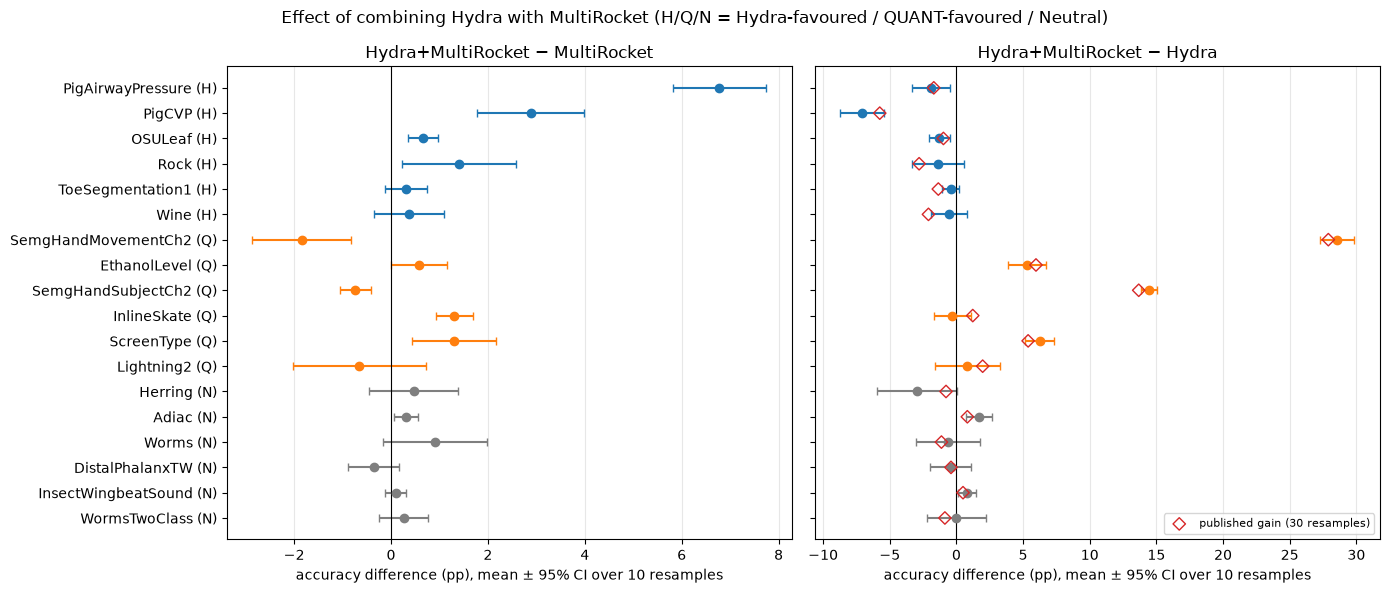

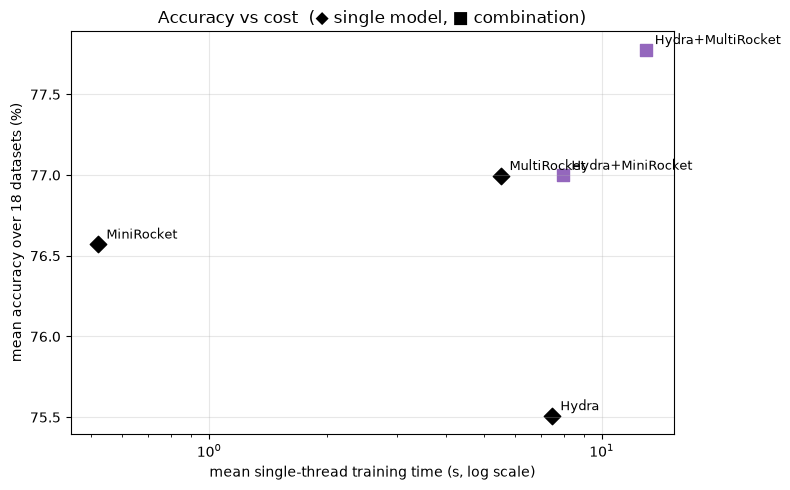

In [14]:
colors = {"Hydra-favoured": "tab:blue", "QUANT-favoured": "tab:orange", "Neutral": "tab:gray"}

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, (a, b) in zip(axes, [("Hydra+MultiRocket", "MultiRocket"), ("Hydra+MultiRocket", "Hydra")]):
    diffs = [(acc.loc[d, a] - acc.loc[d, b]) * 100 for d in DATASETS]
    means = [x.mean() for x in diffs]
    ci = [1.96 * x.std(ddof=1) / np.sqrt(len(x)) for x in diffs]
    for i, d in enumerate(DATASETS):
        ax.errorbar(means[i], i, xerr=ci[i], fmt="o", color=colors[GROUP_OF[d]], capsize=3)
    if b == "Hydra":
        ax.scatter(paper["paper gain H+MR over Hydra (pp)"], np.arange(len(DATASETS)), marker="D",
                   facecolors="none", edgecolors="tab:red", s=40, label="published gain (30 resamples)", zorder=3)
        ax.legend(fontsize=8, loc="lower right")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{a} − {b}")
    ax.set_xlabel("accuracy difference (pp), mean ± 95% CI over 10 resamples")
    ax.grid(True, axis="x", alpha=0.3)
axes[0].set_yticks(np.arange(len(DATASETS)))
axes[0].set_yticklabels([f"{d} ({GROUP_OF[d][0]})" for d in DATASETS])
axes[0].invert_yaxis()
fig.suptitle("Effect of combining Hydra with MultiRocket (H/Q/N = Hydra-favoured / QUANT-favoured / Neutral)")
fig.tight_layout()
fig.savefig(PLOT_DIR / "hydra_multirocket_gain.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for cfg in CONFIGS:
    ax.scatter(cost.loc[cfg, "train_seconds"], cost.loc[cfg, "mean_acc_%"], s=70,
               marker="s" if "+" in cfg else "D", color="tab:purple" if "+" in cfg else "black")
    ax.annotate(cfg, (cost.loc[cfg, "train_seconds"], cost.loc[cfg, "mean_acc_%"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("mean single-thread training time (s, log scale)")
ax.set_ylabel("mean accuracy over 18 datasets (%)")
ax.set_title("Accuracy vs cost  (◆ single model, ■ combination)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "accuracy_vs_train_time.png", dpi=200)
plt.show()

### Cell 14 - Save summary table

In [15]:
summary = (runs.groupby(["dataset", "config"])
           .agg(group=("group", "first"), n_resamples=("accuracy", "size"),
                mean_accuracy=("accuracy", "mean"), std_accuracy=("accuracy", "std"),
                mean_macro_f1=("macro_f1", "mean"), n_features=("n_features", "first"),
                pct_alpha_at_1000=("alpha_at_upper", "mean"))
           .reset_index()
           .merge(timing[["dataset", "config", "train_seconds", "test_seconds"]]
                  .rename(columns={"train_seconds": "train_seconds_isolated", "test_seconds": "test_seconds_isolated"}),
                  on=["dataset", "config"], how="left"))
summary.to_csv(OUT_DIR / "mrh_summary.csv", index=False)
print("Saved", OUT_DIR / "mrh_summary.csv", "|", len(summary), "rows")

Saved c:\Users\User\Documents\hydra-time-series-project\results\Aarti\multirocket_hydra\mrh_summary.csv | 90 rows


## Results and interpretation

**Run:** 18 datasets × 10 resamples × 5 models (900 results); cost from isolated single-thread runs on resample 0 of every dataset.

### 1. The paper's combination results reproduce
| Model | Mean ours − paper | Mean \|ours − paper\| | Within expected variance |
|---|---:|---:|---:|
| Hydra | +0.15 pp | 0.70 pp | **18 / 18** |
| Hydra+MiniRocket | +0.09 pp | 0.47 pp | **18 / 18** |
| Hydra+MultiRocket | +0.22 pp | 0.53 pp | **18 / 18** |

The **gain from adding MultiRocket to Hydra also follows the published gain dataset by dataset** (Spearman ρ = 0.89, p < 10⁻⁶): large where the paper reports large gains (SemgHandMovementCh2 +28.6 pp vs +27.9 pp published, SemgHandSubjectCh2 +14.5 vs +13.7, EthanolLevel +5.3 vs +6.0), and negative where the paper reports losses (PigCVP −7.1 vs −5.8). On these 18 datasets our mean gain over Hydra is +2.27 pp against +2.20 pp published. The paper's combination claim stands up to scrutiny.

### 2. Adding Hydra to MultiRocket helps - modestly, and only on some datasets
Mean accuracy over the 18 datasets: **Hydra+MultiRocket 77.8 %**, MultiRocket 77.0 %, Hydra+MiniRocket 77.0 %, MiniRocket 76.6 %, Hydra 75.5 %.

| Comparison | All 18 | Hydra-favoured | QUANT-favoured | Neutral |
|---|---|---|---|---|
| Hydra+MultiRocket vs MultiRocket | **+0.78 pp** (14 / 4, p = 0.054) | +2.07 (6 / 0, p = 0.031) | −0.01 (3 / 3) | +0.28 (5 / 1) |
| Hydra+MultiRocket vs Hydra | +2.27 pp (7 / 10, p = 0.83) | −2.11 (0 / 6, p = 0.031) | +9.18 (5 / 1) | −0.26 (2 / 3) |
| Hydra+MiniRocket vs MiniRocket | +0.43 pp (13 / 5, p = 0.17) | +0.88 | −0.10 | +0.50 |

(win / loss counts are datasets; per split, Hydra+MultiRocket beats MultiRocket on 96 of 180 splits, ties on 41, loses on 43.)

* The question the published file cannot answer, **does Hydra add to MultiRocket?**, gets a cautious yes: +0.8 pp, consistent in direction (14 of 18 datasets) but just short of significance with 18 datasets (p = 0.054).
* As with QUANT × Hydra, the combination behaves like a **robust compromise** rather than a uniformly better model: it beats MultiRocket where Hydra is strong (all 6 Hydra-favoured datasets), but loses to Hydra itself there (all 6), and it equals MultiRocket where MultiRocket is strong.

### 3. Other observations
* **MiniRocket is remarkably strong on the Pig datasets** (PigAirwayPressure 87.1 % vs MultiRocket 65.6 % and Hydra 74.3 %), while MultiRocket is far better on the QUANT-favoured group (+5.4 pp over MiniRocket, 6 / 0 datasets, p = 0.031). Neither ROCKET variant dominates.
* **The README α grid is binding for every model:** the selected α is the largest value (1000) in 49–64 % of runs, consistent with `02_hydra_alpha_grid.ipynb`.

### 4. Computational cost (isolated single-thread runs, mean over 18 datasets)
| Model | Train (s) | Test (s) | × MultiRocket (train / test) | Features | Mean acc. |
|---|---:|---:|---|---:|---:|
| MiniRocket | 0.52 | 0.47 | 0.09 / 0.07 | 9,996 | 76.6 % |
| MultiRocket | 5.54 | 6.94 | 1.00 / 1.00 | 49,728 | 77.0 % |
| Hydra | 7.47 | 10.41 | 1.35 / 1.50 | ~6,900 | 75.5 % |
| Hydra+MiniRocket | 7.97 | 10.88 | 1.44 / 1.57 | ~16,900 | 77.0 % |
| Hydra+MultiRocket | 13.00 | 17.35 | **2.35 / 2.50** | ~56,700 | 77.8 % |

* On these long series Hydra is *more* expensive than MultiRocket (1.35× training, 1.5× test), so Hydra+MultiRocket costs about **2.4× MultiRocket** for +0.8 pp.
* MiniRocket is ~10× cheaper than MultiRocket for −0.4 pp; **Hydra+MiniRocket** matches MultiRocket's accuracy and is the cheapest combination.

### 5. Comparison with the QUANT × Hydra combinations (same splits, same Hydra kernels)
Both notebooks use identical splits and Hydra seeds (Hydra's accuracy is identical in both, 75.51 %), so the combinations can be compared directly:

| Partner for Hydra | Mean acc. | Train (s) | Test (s) | vs Hydra+MultiRocket |
|---|---:|---:|---:|---|
| MultiRocket (`Hydra+MultiRocket`, paper) | 77.8 % | 13.0 | 17.4 | - |
| QUANT, late fusion (`Q+Hydra`) | **79.2 %** | 11.4 | 10.6 | +1.39 pp (12 / 6 datasets, p = 0.09) |
| QUANT + dictionary half (`Q+H-dict`) | 79.1 % | **8.8** | **7.1** | +1.27 pp (11 / 7, p = 0.15) |

Even though **QUANT alone is less accurate than MultiRocket alone** (−2.0 pp on these datasets), QUANT is the better *partner* for Hydra: more accurate on average and much cheaper (Q+H-dict: 0.68× the training and 0.41× the test time of Hydra+MultiRocket). An interval method complements Hydra better than another convolutional method does. This is a direction for improvement, not a proven win: the difference is not significant over 18 datasets.

### Caveats
* 10 resamples (paper: 30); 18 datasets chosen for a QUANT-vs-Hydra contrast, so they are harder and more varied than an average UCR sample.
* Timings: one resample on one laptop; ratios are meaningful, absolute seconds are not comparable with the paper's cluster. Timings from the two notebooks were measured in separate isolated runs on the same machine (Hydra: 7.15 s vs 7.47 s training, i.e. ~4 % run-to-run variation).
